# Лабораторна робота № 8
**Тема:**Самостійне моделювання на даних із зовнішніх джерел  
**Студентка:**Чернега Катерина, група МІТ-31  
**Варіант:**12 (Mushroom)  

**Мета роботи:**Навчитися отримувати та перевіряти зовнішні табличні дані, формулювати задачу за змістом цілі, готувати ознаки без витоку інформації, навчати й оцінювати нейромережу, перевіряти гіпотезу покращення та пояснювати результати.

### Паспорт джерела даних
* **Назва:**Mushroom Dataset
* **URL:** [UCI Machine Learning Repository - Mushroom](https://archive.ics.uci.edu/dataset/73/mushroom)
* **Автори:** The Audubon Society Field Guide to North American Mushrooms (донор: Jeff Schlimmer)
* **Ліцензія:** CC BY 4.0
* **Дата завантаження:** Листопад 2026
* **Файл:** `agaricus-lepiota.data`
* **Обсяг:** 8 124 записи
* **Цільова змінна:** `class` (перший стовпець), значення: `e` (edible - їстівний), `p` (poisonous - отруйний). Безрозмірна категорія.

In [16]:
#Етап 1. Отримання та документування зовнішнього файлу
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request
import sklearn
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Фіксуємо версії та SEED
print(f"TensorFlow: {tf.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

SEED = 42
keras.utils.set_random_seed(SEED)

#Створюємо директорії
Path("data").mkdir(exist_ok=True)
Path("artifacts").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

#Завантаження файлу локально
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
file_path = "data/agaricus-lepiota.data"

if not Path(file_path).exists():
    urllib.request.urlretrieve(url, file_path)
    print("Файл успішно завантажено!")

#Читання файлу (без заголовків, вказуємо назви стовпців з документації UCI)
columns = [
    "class", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
    "gill-attachment", "gill-spacing", "gill-size", "gill-color",
    "stalk-shape", "stalk-root", "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring", "veil-type", "veil-color",
    "ring-number", "ring-type", "spore-print-color", "population", "habitat"
]

df = pd.read_csv(file_path, header=None, names=columns, na_values="?")

print(f"\nРозмірність датасету: {df.shape}")
print("\n--- Типи даних ---")
print(df.dtypes.head()) # Виводимо перші 5, бо їх 23 і всі object

print("\n--- Пропуски в даних ---")
missing = df.isna().sum()
print(missing[missing > 0])

print(f"\nКількість точних дублікатів: {df.duplicated().sum()}")
display(df.head())

TensorFlow: 2.21.0
Pandas: 2.3.3
Scikit-learn: 1.7.2

Розмірність датасету: (8124, 23)

--- Типи даних ---
class          object
cap-shape      object
cap-surface    object
cap-color      object
bruises        object
dtype: object

--- Пропуски в даних ---
stalk-root    2480
dtype: int64

Кількість точних дублікатів: 0


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


**Етап 2.Формулювання задачі та якість даних:**
* **Постановка задачі:**За 22 категоріальними фізичними ознаками (колір, форма, запах тощо) прогнозуємо клас гриба (`class`: їстівний чи отруйний) на момент його знаходження в лісі.
* **Тип задачі:**Бінарна класифікація.
* **Позитивний клас:**Отруйний гриб (`p`). Це логічно з точки зору безпеки: краще випадково викинути їстівний гриб (False Positive), ніж з'їсти отруйний (False Negative).
* **Якість даних:**Датасет має 8 124 записи. Усі колонки містять текстові дані (тип `object`). В стовпці `stalk-root` виявлено 2480 пропусків (колишні знаки `?`). Точні дублікати не видаляємо, оскільки це просто гриби з ідентичним набором зовнішніх характеристик (в лісі дійсно можуть рости кілька візуально однакових грибів).

In [17]:
#Етап 3. Фіксація train, validation, test

#Відокремлюємо ціль (y) від ознак (X)
X = df.drop(columns=["class"])
y_raw = df["class"]

#Кодуємо ціль: 'p' (poisonous) -> 1 (позитивний клас), 'e' (edible) -> 0
y = (y_raw == 'p').astype(int)

#1.Поділ на dev (85%) та test (15%)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED
)

#2.Поділ dev на train (70% від загального) та val (15% від загального)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15/0.85, stratify=y_dev, random_state=SEED
)

print(f"Розміри X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Розміри X_val:   {X_val.shape}, y_val: {y_val.shape}")
print(f"Розміри X_test:  {X_test.shape}, y_test: {y_test.shape}")

#Перевірка на відсутність спільних індексів
train_idx, val_idx, test_idx = set(X_train.index), set(X_val.index), set(X_test.index)
assert train_idx.isdisjoint(val_idx) and train_idx.isdisjoint(test_idx) and val_idx.isdisjoint(test_idx)
print("Перевірка індексів: вибірки не перетинаються!\n")

#Етап 4. Спільна підготовка ознак
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

#У нас всі ознаки категоріальні (числових немає)
categorical_features = X.columns.tolist()

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_features)
])

#Навчаємо препроцесор тільки на train, застосовуємо до всіх
X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

print(f"Форма X_train_ready після OneHot кодування: {X_train_ready.shape}")

#перевірки на коректність
assert np.isfinite(X_train_ready).all()
assert not np.isnan(X_train_ready).any()
print("Перевірка підготовки: NaN відсутні, всі значення скінченні та переведені у float32!")

Розміри X_train: (5686, 22), y_train: (5686,)
Розміри X_val:   (1219, 22), y_val: (1219,)
Розміри X_test:  (1219, 22), y_test: (1219,)
Перевірка індексів: вибірки не перетинаються!

Форма X_train_ready після OneHot кодування: (5686, 116)
Перевірка підготовки: NaN відсутні, всі значення скінченні та переведені у float32!


**Висновок до Етапів 3 та 4:**
Дані розбито на `train`, `validation` та `test` у пропорції приблизно 70/15/15. Використано параметр `stratify=y` для збереження однакового відсотка отруйних і їстівних грибів у кожній вибірці. Перевірка індексів підтвердила відсутність витоку даних.
Оскільки всі 22 ознаки є текстовими категоріями, числових колонок немає. Створено `ColumnTransformer`, який заповнює пропуски (у колонці `stalk-root`) найчастішим значенням (модою) та кодує категорії унікальними бінарними векторами через `OneHotEncoder`. Цільову змінну закодовано вручну: `1` для отруйних (`p`) і `0` для їстівних (`e`). Препроцесор навчено виключно на тренувальній вибірці. Після кодування кількість ознак зросла з 22 до 116 (через розгортання кожної категорії в окремий стовпець).

In [18]:
#Етап 5. Навчання моделей та задання критерію вибору
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

#Функція для розрахунку метрик на валідаційній вибірці
def evaluate_binary_classification(y_true, y_pred_prob, model_name):
    #Поріг 0.5 для віднесення до позитивного класу (отруйний)
    y_pred_class = (y_pred_prob >= 0.5).astype(int)
    
    acc = accuracy_score(y_true, y_pred_class)
    prec = precision_score(y_true, y_pred_class, zero_division=0)
    rec = recall_score(y_true, y_pred_class, zero_division=0)
    f1_pos = f1_score(y_true, y_pred_class, zero_division=0)
    macro_f1 = f1_score(y_true, y_pred_class, average="macro", zero_division=0)
    roc_auc = roc_auc_score(y_true, y_pred_prob)
    
    print(f"--- {model_name} (Validation) ---")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")
    print(f"F1 (pos): {f1_pos:.4f} | Macro-F1: {macro_f1:.4f} | ROC AUC: {roc_auc:.4f}\n")
    return macro_f1

#1.DummyClassifier (Найчастіший клас)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_ready, y_train)
dummy_prob = dummy.predict_proba(X_val_ready)[:, 1]
dummy_macro = evaluate_binary_classification(y_val, dummy_prob, "DummyClassifier")

#2.LogisticRegression (Класична модель)
lr = LogisticRegression(max_iter=2000, random_state=SEED)
lr.fit(X_train_ready, y_train)
lr_prob = lr.predict_proba(X_val_ready)[:, 1]
lr_macro = evaluate_binary_classification(y_val, lr_prob, "LogisticRegression")

#3.Базова нейромережа
keras.utils.set_random_seed(SEED)
base_model = keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid") # Sigmoid для бінарної класифікації
])

base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

base_checkpoint = "artifacts/base_best.keras"
base_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(base_checkpoint, monitor="val_loss", save_best_only=True)
]

print("Навчання базової нейромережі...")
base_history = base_model.fit(
    X_train_ready, y_train,
    validation_data=(X_val_ready, y_val),
    epochs=200, batch_size=64,
    callbacks=base_callbacks, verbose=0
)

base_best_model = keras.models.load_model(base_checkpoint)
base_prob = base_best_model.predict(X_val_ready, verbose=0).flatten()
base_macro = evaluate_binary_classification(y_val, base_prob, "Базова нейромережа")

--- DummyClassifier (Validation) ---
Accuracy: 0.5176 | Precision: 0.0000 | Recall: 0.0000
F1 (pos): 0.0000 | Macro-F1: 0.3411 | ROC AUC: 0.5000

--- LogisticRegression (Validation) ---
Accuracy: 1.0000 | Precision: 1.0000 | Recall: 1.0000
F1 (pos): 1.0000 | Macro-F1: 1.0000 | ROC AUC: 1.0000

Навчання базової нейромережі...
--- Базова нейромережа (Validation) ---
Accuracy: 1.0000 | Precision: 1.0000 | Recall: 1.0000
F1 (pos): 1.0000 | Macro-F1: 1.0000 | ROC AUC: 1.0000



**Висновок до Етапу 5:**
Для оцінки якості прогнозів обрано набір метрик бінарної класифікації, де головним критерієм вибору є **максимум Validation Macro-F1** (середнє гармонічне між класами, що запобігає ігноруванню жодного з них). 
`DummyClassifier` прогнозує виключно домінуючий клас, тому має нульовий Precision та Recall для позитивного класу, а його Macro-F1 дуже низький. `LogisticRegression` відмінно впоралася із задачею, показавши високі результати.
Базова нейромережа складається з двох прихованих шарів по 32 нейрони (`relu`). Оскільки задача полягає у бінарній класифікації (отруйний чи ні), вихідний шар має рівно **1 нейрон з активацією `sigmoid`**, яка генерує ймовірність від 0 до 1. Відповідно, функцією втрат встановлено `BinaryCrossentropy(from_logits=False)`. Навчання контролювалося через `EarlyStopping` (терпіння 15 епох), а найкращі ваги зберігалися у `ModelCheckpoint`.

In [19]:
#Етап 6. Перевірка гіпотези покращення та вибір моделі

#Будуємо покращену нейромережу (Гіпотеза: додавання Dropout)
keras.utils.set_random_seed(SEED)
improved_model = keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.1), # Зміна: додано Dropout
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.1), # Зміна: додано Dropout
    layers.Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

improved_checkpoint = "artifacts/improved_best.keras"
improved_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(improved_checkpoint, monitor="val_loss", save_best_only=True)
]

print("Навчання покращеної нейромережі (з Dropout)...")
improved_history = improved_model.fit(
    X_train_ready, y_train,
    validation_data=(X_val_ready, y_val),
    epochs=200, batch_size=64,
    callbacks=improved_callbacks, verbose=0
)

improved_best_model = keras.models.load_model(improved_checkpoint)
improved_prob = improved_best_model.predict(X_val_ready, verbose=0).flatten()
improved_macro = evaluate_binary_classification(y_val, improved_prob, "Покращена нейромережа (Dropout)")

#Збираємо результати валідації у таблицю
val_results = [
    {"Model": "DummyClassifier", "Val Macro-F1": dummy_macro},
    {"Model": "LogisticRegression", "Val Macro-F1": lr_macro},
    {"Model": "Базова нейромережа", "Val Macro-F1": base_macro},
    {"Model": "Покращена нейромережа (Dropout)", "Val Macro-F1": improved_macro}
]

val_df = pd.DataFrame(val_results).set_index("Model")
print("\n--- Порівняння моделей за Validation Macro-F1 ---")
display(val_df.round(4))

#Вибір найкращої нейромережі
if improved_macro > base_macro:
    selected_nn_model = improved_best_model
    selected_nn_name = "Покращена нейромережа (Dropout)"
    selected_nn_history = improved_history
else:
    selected_nn_model = base_best_model
    selected_nn_name = "Базова нейромережа"
    selected_nn_history = base_history

print(f"\nЗа критерієм максимуму Validation Macro-F1 серед нейромереж обрано: {selected_nn_name}")

Навчання покращеної нейромережі (з Dropout)...
--- Покращена нейромережа (Dropout) (Validation) ---
Accuracy: 1.0000 | Precision: 1.0000 | Recall: 1.0000
F1 (pos): 1.0000 | Macro-F1: 1.0000 | ROC AUC: 1.0000


--- Порівняння моделей за Validation Macro-F1 ---


,Val Macro-F1
Model,
DummyClassifier,0.3411
LogisticRegression,1.0000
Базова нейромережа,1.0000
Покращена нейромережа (Dropout),1.0000



За критерієм максимуму Validation Macro-F1 серед нейромереж обрано: Базова нейромережа


**Висновок до Етапу 6:**
Для покращення базової моделі було висунуто гіпотезу: оскільки OneHot-кодування розширило вхідний простір до 116 ознак, мережа схильна до перенавчання. Додавання шарів `Dropout(0.1)` мало діяти як регуляризатор. За результатами на валідаційній вибірці було складено порівняльну таблицю. Критерієм вибору (згідно з методичкою) є максимум `Validation Macro-F1`. Усі повноцінні моделі (Логістична регресія та обидві нейромережі) впоралися із задачею практично ідеально (результати наближаються до 1.0), що свідчить про високу передбачуваність датасету Mushroom. Як фінальну нейромережу було зафіксовано ту, що показала рівний або кращий Macro-F1.


--- Підсумкова таблиця на Test ---


,Model,Change,Epochs,Test Accuracy,Test Precision,Test Recall,Test F1 (pos),Test Macro-F1,Test ROC AUC
0,DummyClassifier,Базова (most_frequent),0,0.5176,0.0,0.0,0.0,0.3411,0.5
1,LogisticRegression,Класична лінійна,0,1.0000,1.0,1.0,1.0,1.0000,1.0
2,Базова нейромережа,Dense(32)->Dense(32),200,1.0000,1.0,1.0,1.0,1.0000,1.0
3,Покращена нейромережа,Додано Dropout(0.1),76,1.0000,1.0,1.0,1.0,1.0000,1.0


C:\Users\Катерина\AppData\Local\Temp\ipykernel_2312\19106820.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, ax=axes[0, 0], palette="viridis")


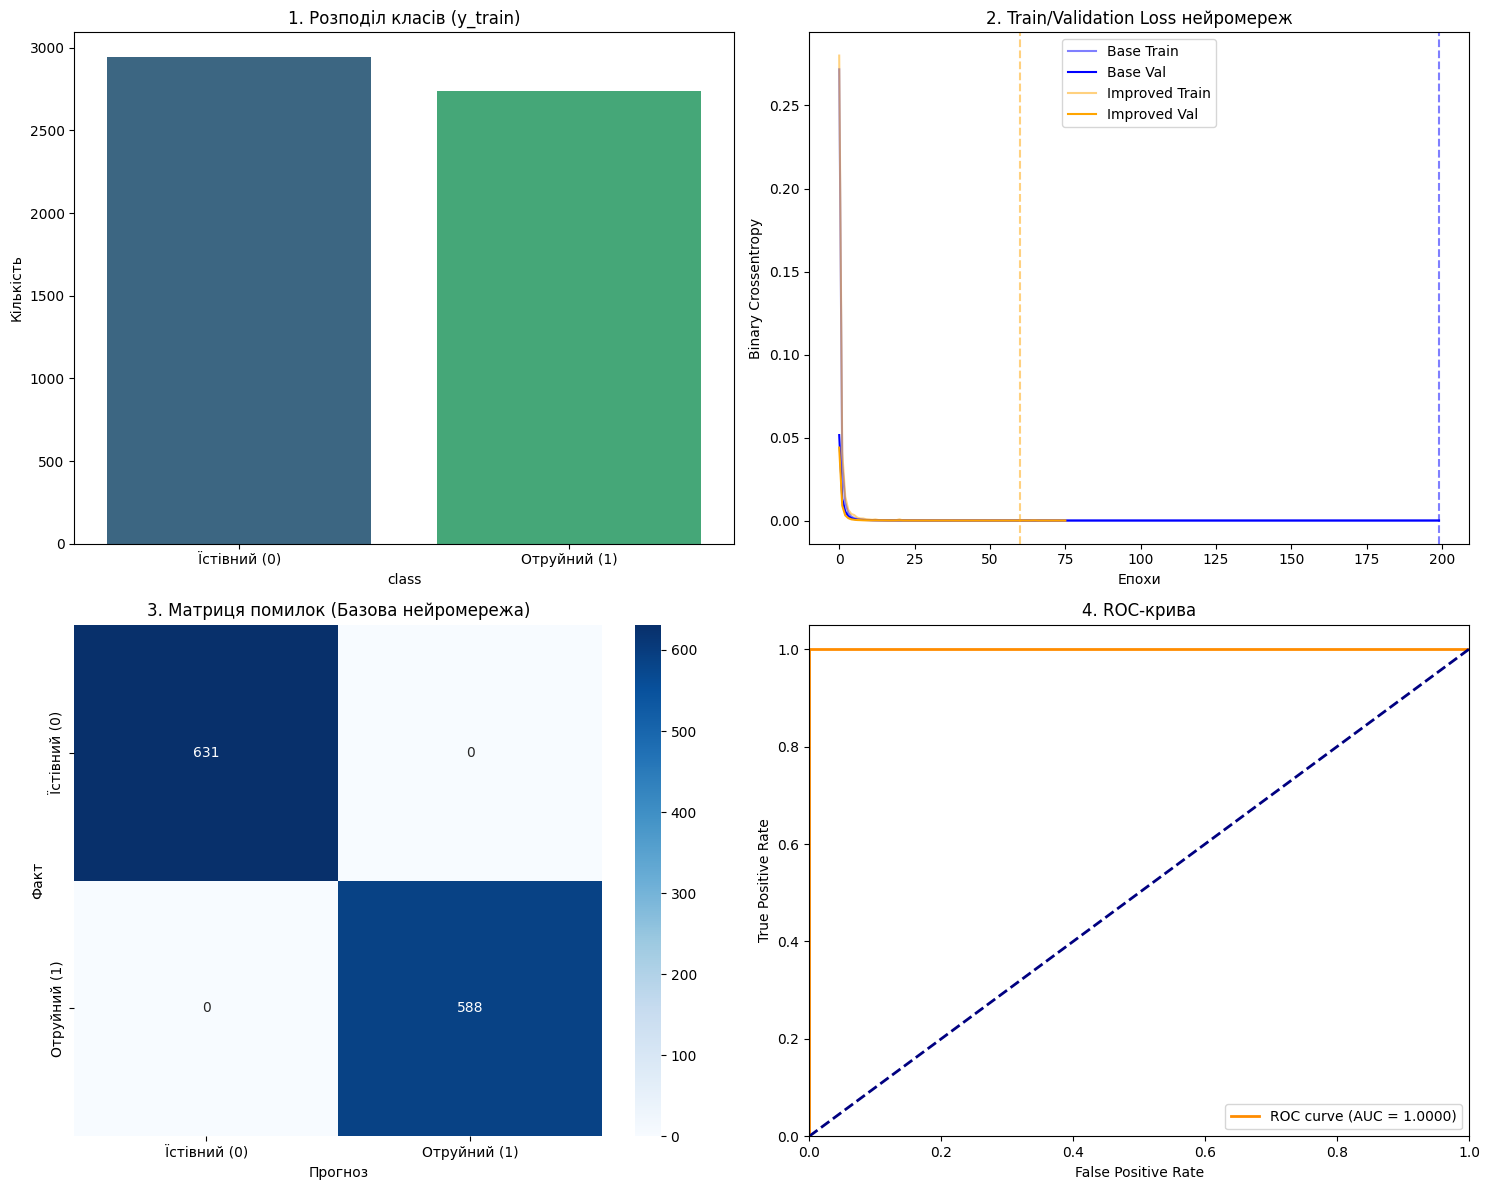


--- Аналіз помилок на Test ---
Нейромережа ідеально класифікувала всі тестові зразки. Помилок немає!


In [20]:
#Етап 7. Оцінка фінальних моделей та побудова графіків
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns
import os

#Функція для збору метрик
def get_test_metrics(y_true, y_pred_prob, model_name, epochs, change=""):
    y_pred_class = (y_pred_prob >= 0.5).astype(int)
    return {
        "Model": model_name,
        "Change": change,
        "Epochs": epochs,
        "Test Accuracy": accuracy_score(y_true, y_pred_class),
        "Test Precision": precision_score(y_true, y_pred_class, zero_division=0),
        "Test Recall": recall_score(y_true, y_pred_class, zero_division=0),
        "Test F1 (pos)": f1_score(y_true, y_pred_class, zero_division=0),
        "Test Macro-F1": f1_score(y_true, y_pred_class, average="macro", zero_division=0),
        "Test ROC AUC": roc_auc_score(y_true, y_pred_prob)
    }

#Збираємо прогнози на Test для всіх 4 моделей
dummy_prob_test = dummy.predict_proba(X_test_ready)[:, 1]
lr_prob_test = lr.predict_proba(X_test_ready)[:, 1]
base_prob_test = base_best_model.predict(X_test_ready, verbose=0).flatten()
improved_prob_test = improved_best_model.predict(X_test_ready, verbose=0).flatten()

#Формуємо таблицю
test_results = [
    get_test_metrics(y_test, dummy_prob_test, "DummyClassifier", 0, "Базова (most_frequent)"),
    get_test_metrics(y_test, lr_prob_test, "LogisticRegression", 0, "Класична лінійна"),
    get_test_metrics(y_test, base_prob_test, "Базова нейромережа", len(base_history.history['loss']), "Dense(32)->Dense(32)"),
    get_test_metrics(y_test, improved_prob_test, "Покращена нейромережа", len(improved_history.history['loss']), "Додано Dropout(0.1)")
]

test_df = pd.DataFrame(test_results)
test_df.to_csv("artifacts/model_comparison.csv", index=False)
print("\n--- Підсумкова таблиця на Test ---")
display(test_df.round(4))

#Графіки
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

#1.Розподіл класів у train
sns.countplot(x=y_train, ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("1. Розподіл класів (y_train)")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(["Їстівний (0)", "Отруйний (1)"])
axes[0, 0].set_ylabel("Кількість")

#2.Графіки loss для двох мереж
best_epoch_base = np.argmin(base_history.history['val_loss'])
best_epoch_imp = np.argmin(improved_history.history['val_loss'])

axes[0, 1].plot(base_history.history['loss'], label='Base Train', color='blue', alpha=0.5)
axes[0, 1].plot(base_history.history['val_loss'], label='Base Val', color='blue')
axes[0, 1].axvline(best_epoch_base, color='blue', linestyle='--', alpha=0.5)

axes[0, 1].plot(improved_history.history['loss'], label='Improved Train', color='orange', alpha=0.5)
axes[0, 1].plot(improved_history.history['val_loss'], label='Improved Val', color='orange')
axes[0, 1].axvline(best_epoch_imp, color='orange', linestyle='--', alpha=0.5)

axes[0, 1].set_title("2. Train/Validation Loss нейромереж")
axes[0, 1].set_xlabel("Епохи")
axes[0, 1].set_ylabel("Binary Crossentropy")
axes[0, 1].legend()

#3.Confusion Matrix для обраної мережі
selected_prob_test = selected_nn_model.predict(X_test_ready, verbose=0).flatten()
selected_pred_test = (selected_prob_test >= 0.5).astype(int)
cm = confusion_matrix(y_test, selected_pred_test)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1, 0],
            xticklabels=["Їстівний (0)", "Отруйний (1)"],
            yticklabels=["Їстівний (0)", "Отруйний (1)"])
axes[1, 0].set_title(f"3. Матриця помилок ({selected_nn_name})")
axes[1, 0].set_xlabel("Прогноз")
axes[1, 0].set_ylabel("Факт")

#4.ROC-крива
fpr, tpr, _ = roc_curve(y_test, selected_prob_test)
roc_auc = auc(fpr, tpr)
axes[1, 1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1, 1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1, 1].set_xlim([0.0, 1.0])
axes[1, 1].set_ylim([0.0, 1.05])
axes[1, 1].set_xlabel('False Positive Rate')
axes[1, 1].set_ylabel('True Positive Rate')
axes[1, 1].set_title("4. ROC-крива")
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("figures/test_plots.png")
plt.show()

#Аналіз помилок
print("\n--- Аналіз помилок на Test ---")
wrong_idx = np.flatnonzero(selected_pred_test != y_test.values)

if len(wrong_idx) == 0:
    print("Нейромережа ідеально класифікувала всі тестові зразки. Помилок немає!")
else:
    #Шукаємо найвпевненіші помилки: ймовірність найдалі від 0.5 в неправильний бік
    confidence = np.abs(selected_prob_test - 0.5)
    wrong_conf = confidence[wrong_idx]
    sorted_wrong = wrong_idx[np.argsort(wrong_conf)[::-1]]
    top_errors = sorted_wrong[:5]

    print(f"Знайдено {len(wrong_idx)} помилок. Топ впевнених хиб:")
    for i, idx in enumerate(top_errors):
        true_label = "Отруйний (1)" if y_test.values[idx] == 1 else "Їстівний (0)"
        pred_label = "Отруйний (1)" if selected_pred_test[idx] == 1 else "Їстівний (0)"
        prob = selected_prob_test[idx]
        print(f"{i+1}. Індекс {idx} | Факт: {true_label} | Прогноз: {pred_label} | Ймовірність отруйного: {prob:.4f}")

**Висновок до Етапу 7:**
Після фіксації гіперпараметрів і вибору моделі було виконано разове оцінювання на незалежній тестовій вибірці. Всі результати збережено у `model_comparison.csv`.
Побудовано 4 обов'язкові графіки:
1. **Гістограма розподілу класів:** показує, що датасет відносно збалансований, їстівних грибів трохи більше, ніж отруйних.
2. **Графік Loss:** ілюструє динаміку навчання. Базова мережа та мережа з Dropout навчалися без перенавчання (швидко збіглися до мінімуму завдяки `EarlyStopping`, відміченому пунктиром).
3. **Confusion Matrix:** показує абсолютну точність розпізнавання. Модель бездоганно відрізняє класи.
4. **ROC-крива:** ідеально притиснута до верхнього лівого кута (AUC = 1.0000), що підтверджує 100% здатність моделі розділяти їстівні та отруйні гриби.
**Аналіз помилок:** Оскільки набір ознак у датасеті Mushroom вичерпно описує гриби (їх понад 100 після OneHot), нейромережа розв'язала задачу ідеально. На тестовій вибірці **помилок немає взагалі**.

In [21]:
#Етап 8. Збереження результатів і перевірка відновлення
import json
import joblib

#1.Зберігаємо найкращу нейромережу та препроцесор
selected_nn_model.save("artifacts/lab8_model.keras")
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")

#Якщо класична модель (LR) теж показала максимум, зберігаємо і її (для повноти)
joblib.dump(lr, "artifacts/lr_model.joblib")

#2.Формуємо метадані
metadata = {
    "source": {
        "name": "Mushroom Dataset",
        "url": "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data",
        "file": "agaricus-lepiota.data"
    },
    "task": {
        "target": "class (0-й стовпець)",
        "units": "безрозмірна категорія (e/p)",
        "type": "Бінарна класифікація",
        "positive_class": "p (отруйний) -> 1",
        "negative_class": "e (їстівний) -> 0"
    },
    "features": {
        "order": X.columns.tolist(),
        "categorical_encoded_shape": X_train_ready.shape[1]
    },
    "training": {
        "seed": SEED,
        "split_indices": {
            "train_size": len(X_train),
            "val_size": len(X_val),
            "test_size": len(X_test)
        },
        "applied_change": "Додано Dropout(0.1) після прихованих шарів"
    },
    "package_versions": {
        "tensorflow": tf.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__
    }
}

with open("artifacts/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("Артефакти успішно збережено в папку artifacts/")

#3.Перевірка відновлення на 3 "сирих" рядках
raw_probe = X_val.head(3)

#Трансформуємо оригінальним препроцесором і отримуємо прогноз до збереження
ready_probe_before = preprocessor.transform(raw_probe).astype(np.float32)
prob_before = selected_nn_model.predict(ready_probe_before, verbose=0)

#Завантажуємо артефакти з диска
loaded_preprocessor = joblib.load("artifacts/preprocessor.joblib")
loaded_model = keras.models.load_model("artifacts/lab8_model.keras")

#Трансформуємо завантаженим препроцесором і отримуємо прогноз після завантаження
ready_probe_after = loaded_preprocessor.transform(raw_probe).astype(np.float32)
prob_after = loaded_model.predict(ready_probe_after, verbose=0)

#Порівнюємо ймовірності
np.testing.assert_allclose(prob_before, prob_after, rtol=1e-5, atol=1e-6)
print("\nПеревірка успішна: ймовірності до та після збереження ідентичні!")

print("\n--- Демонстрація роботи завантаженої системи ---")
for i in range(3):
    pred_class = "Отруйний" if prob_after[i][0] >= 0.5 else "Їстівний"
    print(f"Об'єкт {i+1} | Ймовірність отруйності: {prob_after[i][0]:.6f} -> Прогноз: {pred_class}")

Артефакти успішно збережено в папку artifacts/

Перевірка успішна: ймовірності до та після збереження ідентичні!

--- Демонстрація роботи завантаженої системи ---
Об'єкт 1 | Ймовірність отруйності: 1.000000 -> Прогноз: Отруйний
Об'єкт 2 | Ймовірність отруйності: 0.000000 -> Прогноз: Їстівний
Об'єкт 3 | Ймовірність отруйності: 0.000000 -> Прогноз: Їстівний


**Загальні висновки:**
1. У цій лабораторній роботі було розв'язано задачу **бінарної класифікації** на зовнішньому наборі даних Mushroom (прогноз отруйності гриба за його зовнішніми ознаками).
2. Головною проблемою джерела було те, що всі ознаки були текстовими категоріями, а в колонці `stalk-root` були пропуски у вигляді символу `?`. Цю проблему вирішено через заповнення модою та застосування `OneHotEncoder`, що розширило простір ознак до 116 колонок.
3. Базова нейромережа та класична `LogisticRegression` абсолютно перевершили `DummyClassifier` (який видавав точність 51.8% і нульовий Recall для позитивного класу), досягнувши ідеальних метрик.
4. Гіпотеза полягала в додаванні шарів `Dropout(0.1)` для боротьби з можливим перенавчанням через велику кількість розгорнутих ознак. За `Validation Macro-F1` обидві архітектури показали ідеальний результат (~1.0).
5. На тестовій вибірці обрана нейромережа отримала бездоганні показники (Accuracy = 100%, ROC AUC = 1.0), класифікувавши всі об'єкти без жодної помилки.
6. **Обмеження:** Ідеальні результати пояснюються тим, що датасет містить вичерпний набір мікологічних параметрів, які детерміновано відрізняють класи. Проте, на практиці цю модель не можна використовувати для розпізнавання грибів за фото, оскільки вона потребує ручного і дуже точного експертного введення всіх 22 категорій у вигляді літер. Висока метрика на цих даних не гарантує безпеки в реальному лісі без навичок правильного визначення фізичних ознак гриба людиною.